# Phase 2 loss study: which formation loss fills the slots?

v3 showed the problem: trained with Chamfer, the policy fills only ~40% of the goal slots (one slot per drone), because Chamfer has no one-to-one constraint. Here the **same policy, data and training** are run with five formation losses, on **geometric shapes only** (no text): training shapes circle, square, line, triangle, pentagon, random polygon, random polyline; held out star, heart, spiral. 8-96 drones, one slot per drone.

| Loss | Idea | Source |
|---|---|---|
| **chamfer** | each drone to its nearest slot + each slot to its nearest drone | reference (v3) |
| **matching** | Hungarian one-to-one matching, then distance to the own slot | linear assignment |
| **sinkhorn** | entropic optimal transport: a soft one-to-one matching | Cuturi 2013; GeomLoss |
| **energy** | energy distance (MMD): drones and slots compared as distributions, with drone-drone repulsion | Székely & Rizzo; GeomLoss "energy" |
| **laplacian** | matching + the Laplacian formation-similarity error (shape only) | Quan et al., arXiv 2109.07682 / 2210.04048, IEEE T-RO 2023 |
| *dcd* | density-aware Chamfer | Wu et al., NeurIPS 2021: tried, dropped (section 2) |

Everything else is unchanged: shared MLP (39 → 64 → 64 → 2), BPTT through 100 steps, collision + effort penalties, all divided by spacing², shape scored over the last 20% of steps, cosine lr, early stopping. **Model selection: slots filled.** Code: `swarm/formation_losses.py`, settings: `swarm/experiments.py`.

| Section | |
|---|---|
| 1 | Setup |
| 2 | The losses, and a check with the per-scene optimizer |
| 3 | Reference: what a centralized planner reaches |
| 4 | Training |
| 5 | Benchmark per swarm size |
| 6 | Do the drones hold the formation? (speed, goal switching) |
| 7 | Side-by-side GIFs |
| 8 | Summary |

**Stabilized runs.** The first five runs diverged once rollouts reached 100 steps (gradient norms 1e5-1e13; the matching-type losses learned a bang-bang controller). Two energy runs were added with **truncated BPTT** (gradient cut every 25 steps) and a **Huber-like energy distance** (|x| replaced by sqrt(|x|² + (0.2 s)²), smooth near a slot):  (shape scored over the last 20% of steps, as all others) and  (scored at every step). Details: challenges 6-8 in .

## 1. Setup

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:   # find the repo root
    ROOT = ROOT.parent
os.chdir(ROOT)                              # so configs/, data/, runs/ and results/ resolve
sys.path.insert(0, str(ROOT))               # so `import swarm` works

import copy, json
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

from swarm import viz
from swarm.config import load_config, set_overrides
from swarm.dataset import BENCH_N, SHAPE_HELDOUT, SHAPE_TRAIN, load_cell
from swarm.experiments import LOSS_STUDY, LOSS_STUDY_STABLE, LOSS_TAG
ALL_RUNS = LOSS_STUDY | LOSS_STUDY_STABLE
from swarm.formation_losses import assign
from swarm.metrics import slot_error_curve, slot_metrics, steps_to_form
from swarm.losses import close_pairs
from swarm.plan import optimize_plan
from swarm.policy import SharedMLP
from swarm.train import evaluate_benchmark, evaluate_cell, overall, train

cfg = load_config("configs/default.yaml")
LOSSES = list(ALL_RUNS)                          # first study + the stabilized energy runs
TRAIN = os.environ.get("TRAIN", "0") == "1"       # True: train runs that don't exist yet (~40 min each)
COLORS = {"chamfer": "#8A94A6", "matching": "#C8402F", "sinkhorn": "#2F6DB5", "energy": "#13867A",
          "laplacian": "#B07A1E", "energy_stable": "#0B5D52", "energy_stable_all": "#6BC4B5", "optimum": "#000000"}
GIFS, FIGS = Path("results/gifs"), Path("results/figures")
SPLITS = {"train": SHAPE_TRAIN, "heldout": SHAPE_HELDOUT}
def cfg_for(loss):
    c = load_config("configs/default.yaml")
    return set_overrides(c, ALL_RUNS[loss])
print("losses:", LOSSES)

losses: ['chamfer', 'matching', 'sinkhorn', 'energy', 'laplacian', 'energy_stable', 'energy_stable_all']


## 2. The losses, and a check with the per-scene optimizer

All are per scene, averaged over the last 20% of steps, made dimensionless with the drone spacing $s$. $p_i$ drones, $q_j$ slots, $N$ of each.

- **chamfer**: $\frac1N\sum_i \min_j |p_i-q_j|^2 + \frac1N\sum_j \min_i |p_i-q_j|^2$, ÷ $s^2$.
- **matching**: $\sigma$ = Hungarian assignment on the final frame (no gradient), held over the window; $\frac1N\sum_i |p_i - q_{\sigma(i)}|^2$ ÷ $s^2$.
- **sinkhorn**: $\sum_{ij}\pi_{ij}|p_i-q_j|^2$ ÷ $s^2$, with $\pi$ the entropic transport plan (marginals $1/N$, blur $\sqrt\varepsilon = 0.25s$). Soft version of matching: a drone between two slots is pulled to both in proportion.
- **energy**: $2\,\mathbb E|p-q| - \mathbb E|p-p'| - \mathbb E|q-q'|$ ÷ $s$, weight 10. Zero only when drones sit on the slots. Its gradient is the mean direction toward all slots minus the mean direction toward all other drones: it never vanishes, and crowded drones push apart.
- **laplacian**: matching + $\|\hat L(P) - \hat L(Q_\sigma)\|_F^2$ with $\hat L = I - D^{-1/2} W D^{-1/2}$, $W_{ij} = |p_i - p_j|^2$ on the complete graph. Invariant to translation, rotation and scale: it scores only the shape, so it needs the matching term to place the formation.

**Check before training**: the Phase 1 optimizer on 8 benchmark scenes per size, same total loss as training. If a loss can't form the shape when optimizing each scene directly, a policy won't learn it either. Here *dcd* (density-aware Chamfer, $\frac12[\text{mean}_i (1 - e^{-d_i/(2s)}/n_i) + \dots]$) fails: its gradient vanishes for drones far from the shape (they start ~10 spacings away), Adam amplifies the leftover noise, and drones drift off. Also note *matching* fails here at 64 drones: the optimizer re-solves the assignment every iteration and it keeps flipping; a policy sees fresh scenes every iteration, so this may not carry over (section 5 tells).

In [2]:
check = {}
for n in (16, 64):
    cell = load_cell(n, "train", families=SHAPE_TRAIN)
    p0, Q, dm = cell["start"][:8], cell["goals"][:8], cell["d_min"][:8]
    for loss in LOSSES + ["dcd"]:
        l = copy.deepcopy(cfg.loss)
        if loss == "dcd":
            l.shape, l.w_shape, l.dcd_scale = "dcd", 100.0, 10.0
        else:
            for k, v in ALL_RUNS[loss].items():
                if k.startswith("loss."):                    # train.tbptt doesn't apply to a fixed plan
                    setattr(l, k.split(".")[1], v)
        tr = optimize_plan(p0, Q, cfg, iters=300, d_min=dm, lcfg=l)["traj"]
        m = slot_metrics(tr[:, -1], Q, dm)
        check[(n, loss)] = (m["filled"].mean().item(), m["slot_error"].mean().item(), m["shared_goals"].mean().item())
print(f"{'loss':11s}" + "".join(f"{'N=' + str(n) + ' filled':>14s}{'err':>7s}" for n in (16, 64)))
for loss in LOSSES + ["dcd"]:
    print(f"{loss:11s}" + "".join(f"{100 * check[(n, loss)][0]:13.0f}%{check[(n, loss)][1]:7.2f}" for n in (16, 64)))

loss          N=16 filled    err   N=64 filled    err
chamfer               88%   0.24           64%   0.88
matching             100%   0.01            7%   1.15
sinkhorn             100%   0.03            9%   1.19
energy               100%   0.01           95%   0.10
laplacian            100%   0.02           14%   1.15
energy_stable          100%   0.02           96%   0.13
energy_stable_all          100%   0.06           46%   0.54
dcd                   82%   0.36           23% 102.56


## 3. Reference: what a centralized planner reaches

The v3 benchmark's stored optimum optimized Chamfer, so it inherits Chamfer's pile-ups (72% filled). The reference here is the centralized answer: **assign slots once with the Hungarian algorithm from the start positions, then optimize the plan** toward the assigned slots (same physics, same collision penalty). This is the upper bound a decentralized policy is compared to, and it is the Phase 3 baseline's idea. Cached in `data/benchmark_v3/assigned_n<N>_<split>.pt`.

In [3]:
def assigned_optimum(n, split):
    path = Path(f"data/benchmark_v3/assigned_n{n}_{split}.pt")
    cell = load_cell(n, split, families=SPLITS[split])
    if path.exists():
        return cell, torch.load(path, weights_only=False)
    l = copy.deepcopy(cfg.loss); l.shape = "assigned"
    Qa = assign(cell["start"], cell["goals"])                    # Hungarian once, from the start
    traj = optimize_plan(cell["start"], Qa, cfg, iters=300, d_min=cell["d_min"], lcfg=l)["traj"]
    out = {"final": traj[:, -1], "curve": slot_error_curve(traj, cell["goals"], cell["d_min"])}
    torch.save(out, path)
    return cell, out

opt_rows = {}
for split in SPLITS:
    opt_rows[split] = []
    for n in BENCH_N:
        cell, o = assigned_optimum(n, split)
        m = slot_metrics(o["final"], cell["goals"], cell["d_min"])
        f = steps_to_form(o["curve"])
        opt_rows[split].append({"n": n, "filled": m["filled"].mean().item(), "slot_error": m["slot_error"].mean().item(),
                                "shared_goals": m["shared_goals"].mean().item(),
                                "steps_to_form": float(f.nanmedian()) if (~f.isnan()).any() else float("nan"),
                                "formed": (~f.isnan()).float().mean().item(),
                                "close_pairs": close_pairs(o["final"], cell["d_min"]).mean().item()})
    print(split, " ".join(f"N={r['n']}: {100 * r['filled']:.0f}%" for r in opt_rows[split]))

train N=8: 100% N=16: 100% N=24: 100% N=32: 100% N=48: 100% N=64: 100% N=96: 100%


heldout N=8: 100% N=16: 100% N=24: 100% N=32: 100% N=48: 100% N=64: 100% N=96: 100%


## 4. Training

Five runs, identical except for the loss (`swarm/experiments.py`). They were trained in parallel from the command line with the same `swarm.train.train` call as below; set `TRAIN=1` to train any that are missing.

loss        iterations  stopped  minutes  best it  val filled
chamfer           2500     2500     59.0     1500         45%
matching          2000     2000     51.2     1000         20%
sinkhorn          1750     1750     46.5      750         17%
energy            2000     2000     52.7     1000         26%
laplacian         2000     2000     53.2     1000         30%
energy_stable       3000        -     50.3     2500         69%
energy_stable_all       3000        -     53.1     2750         58%


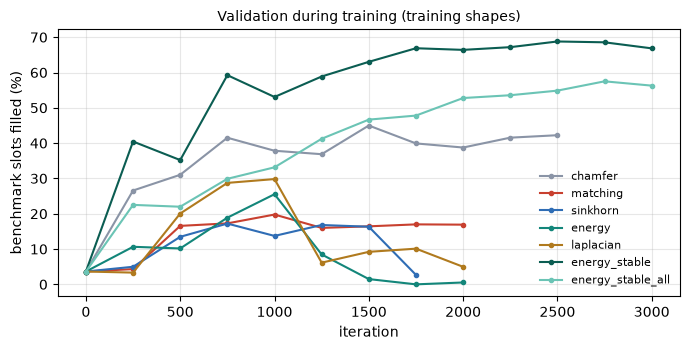

In [4]:
for loss in LOSSES:
    run = Path("runs") / LOSS_TAG.format(loss)
    if TRAIN and not (run / "history.json").exists():
        train(cfg_for(loss), run_dir=run, families=SHAPE_TRAIN)
policies, histories = {}, {}
fig, ax = plt.subplots(figsize=(7, 3.6))
print(f"{'loss':11s}{'iterations':>11s}{'stopped':>9s}{'minutes':>9s}{'best it':>9s}{'val filled':>12s}")
for loss in LOSSES:
    run = Path("runs") / LOSS_TAG.format(loss)
    h = json.loads((run / "history.json").read_text())
    ck = torch.load(run / "best.pt", weights_only=False)
    policies[loss] = SharedMLP.load(run / "best.pt").eval()
    Path("results/models").mkdir(parents=True, exist_ok=True)
    policies[loss].save(f"results/models/{LOSS_TAG.format(loss)}.pt", **{k: v for k, v in ck.items() if k not in ("hparams", "state_dict")})
    histories[loss] = h
    print(f"{loss:11s}{len(h['train']):11d}{str(h['stopped_at'] or '-'):>9s}{h['train'][-1]['time'] / 60:9.1f}{ck['it']:9d}"
          f"{100 * ck['val_filled']:11.0f}%")
    ax.plot([v["it"] for v in h["val"]], [100 * v["filled"] for v in h["val"]], "o-", ms=3, color=COLORS[loss], label=loss)
ax.set_xlabel("iteration"); ax.set_ylabel("benchmark slots filled (%)"); ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=8)
ax.set_title("Validation during training (training shapes)", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "phase2_losses_training.png"); plt.show()

## 5. Benchmark per swarm size

Same scenes for every loss (v3 benchmark, geometric shapes only: 28 training-shape scenes and up to 12 held-out per size). Slot metrics from `swarm/metrics.py`; *steps to form* = first step after which the slot error stays below 0.5 spacings (median over the scenes that formed; *formed* = share that did).

In [5]:
rows = {loss: {sp: evaluate_benchmark(policies[loss], cfg, sp, form=True, families=fams) for sp, fams in SPLITS.items()}
        for loss in LOSSES}
KEYS = ["filled", "slot_error", "steps_to_form", "formed", "shared_goals", "close_pairs"]
summary = {loss: {sp: {k: overall(rows[loss][sp], k) for k in KEYS} for sp in SPLITS} for loss in LOSSES}
summary["optimum"] = {sp: {k: overall(opt_rows[sp], k) for k in KEYS} for sp in SPLITS}
for sp in SPLITS:
    print(f"--- {sp} shapes, mean over N = {BENCH_N}")
    print(f"{'':11s}{'filled':>8s}{'slot err':>10s}{'form@':>7s}{'formed':>8s}{'shared':>8s}{'close':>7s}")
    for k in LOSSES + ["optimum"]:
        s = summary[k][sp]
        print(f"{k:11s}{100 * s['filled']:7.0f}%{s['slot_error']:10.2f}{s['steps_to_form']:7.0f}{100 * s['formed']:7.0f}%"
              f"{100 * s['shared_goals']:7.0f}%{s['close_pairs']:7.1f}")

--- train shapes, mean over N = [8, 16, 24, 32, 48, 64, 96]
             filled  slot err  form@  formed  shared  close
chamfer         45%      2.18     66     12%     18%   10.5
matching        20%      1.13    nan      0%     28%   27.0
sinkhorn        17%      1.35    nan      0%     28%   36.0
energy          26%      1.11     96      2%     27%   13.2
laplacian       30%      0.95     96      4%     27%    9.7
energy_stable     69%      0.61     56     61%      9%    1.4
energy_stable_all     58%      0.84     27     45%     10%    0.5
optimum        100%      0.02     72    100%      0%    0.0
--- heldout shapes, mean over N = [8, 16, 24, 32, 48, 64, 96]
             filled  slot err  form@  formed  shared  close
chamfer         56%      1.21     49     27%     18%    9.4
matching        19%      0.99    nan      0%     28%   28.4
sinkhorn        20%      1.02    nan      0%     27%   35.4
energy          28%      0.82     96     11%     25%   11.0
laplacian       33%      0.74 

/Users/chrisdollo/Documents/Masters/UMD/838B Differentiable Programming/project-drone-swarm/swarm/train.py:101: RuntimeWarning: Mean of empty slice
  return float(np.exp(np.mean(np.log(vals)))) if key == "ratio" else float(np.nanmean(vals))


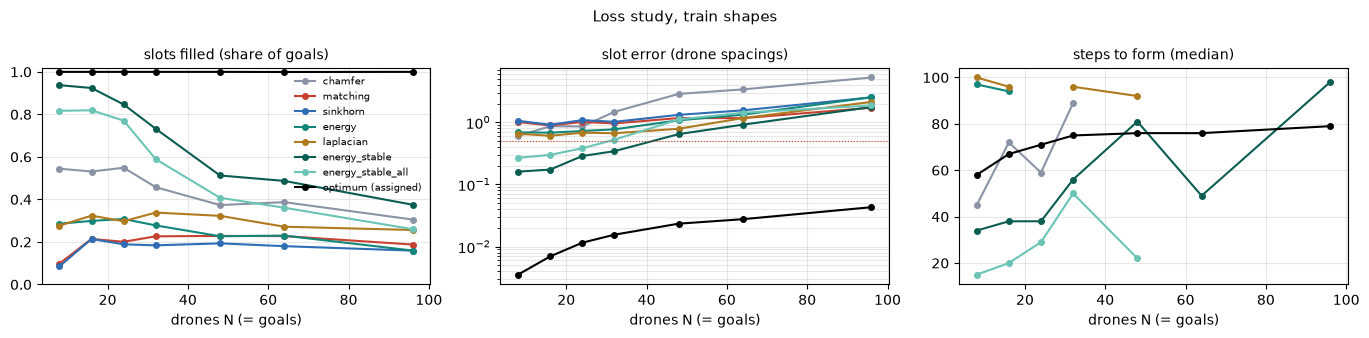

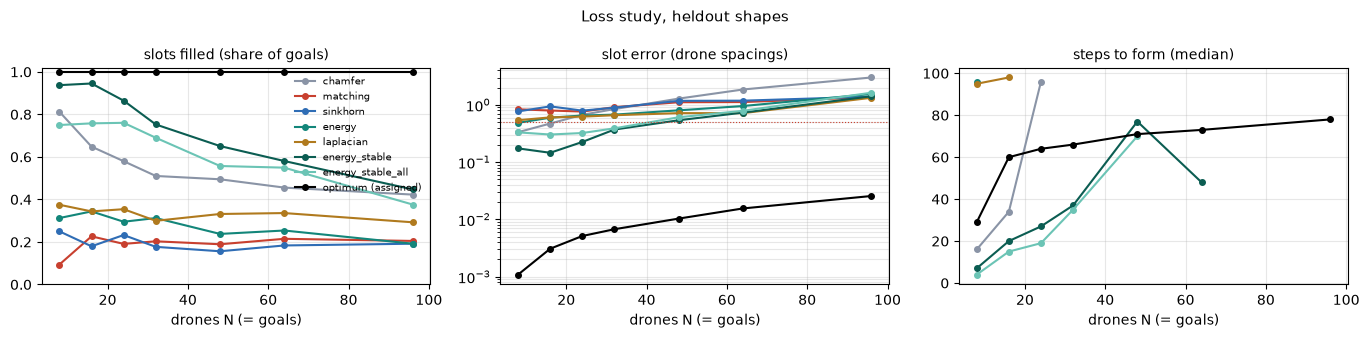

In [6]:
for sp in SPLITS:
    fig = viz.plot_scores_by_n({k: rows[k][sp] for k in LOSSES} | {"optimum (assigned)": opt_rows[sp]},
                               FIGS / f"phase2_losses_{sp}.png", title=f"Loss study, {sp} shapes",
                               colors=COLORS | {"optimum (assigned)": "#000000"})
    plt.show()

## 6. Do the drones hold the formation?

The challenge from Phase 1: scored only on the last frame, drones arrive just in time; scored at every step with Chamfer, they arrive fast but don't settle and swap goals at the last second. Measured over the last 20% of steps of every benchmark scene (all sizes, training shapes):
- **slot error curve**: median slot error at every step (lower = formed; flat = holding)
- **final speed**: mean drone speed at the last step (units/s; 0 = holding still)
- **goal switches**: how many times a drone's nearest slot changes during the last 20 steps (0 = settled on one slot)

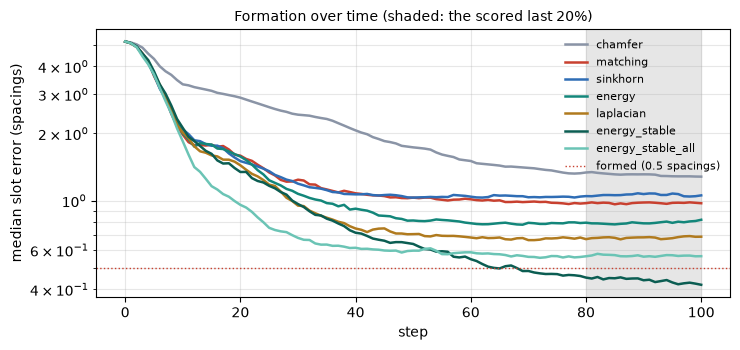

loss         final speed   goal switches (last 20 steps)
chamfer            0.026                            0.16
matching           0.145                            2.21
sinkhorn           0.135                            2.40
energy             0.106                            1.17
laplacian          0.173                            2.17
energy_stable        0.043                            0.34
energy_stable_all        0.030                            0.19


In [7]:
def hold_stats(policy):
    curves, speed, switches = [], [], []
    for n in BENCH_N:
        cell = load_cell(n, "train", families=SHAPE_TRAIN)
        e = evaluate_cell(policy, cell, cfg, form=True)
        tr = e["traj"]
        curves.append(e["curve"])
        speed.append(e["speed"])
        near = torch.cdist(tr[:, -21:], cell["goals"][:, None].expand(-1, 21, -1, -1)).argmin(-1)   # [S, 21, N]
        switches.append((near[:, 1:] != near[:, :-1]).float().sum(1).mean(1))
    return torch.cat(curves), torch.cat(speed), torch.cat(switches)

hold = {loss: hold_stats(policies[loss]) for loss in LOSSES}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for loss, (c, sp, sw) in hold.items():
    ax.semilogy(c.median(0).values, color=COLORS[loss], lw=1.8, label=loss)
    summary[loss]["final_speed"] = sp.mean().item(); summary[loss]["goal_switches"] = sw.mean().item()
ax.axhline(0.5, color="#C8402F", ls=":", lw=1, label="formed (0.5 spacings)")
ax.axvspan(80, 100, color="0.9", zorder=0)
ax.set_xlabel("step"); ax.set_ylabel("median slot error (spacings)"); ax.grid(alpha=0.3, which="both"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Formation over time (shaded: the scored last 20%)", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "phase2_losses_hold.png"); plt.show()
print(f"{'loss':11s}{'final speed':>13s}{'goal switches (last 20 steps)':>32s}")
for loss in LOSSES:
    print(f"{loss:11s}{summary[loss]['final_speed']:13.3f}{summary[loss]['goal_switches']:32.2f}")

## 7. Side by side on identical scenes

Rows: losses. Columns: the same scene (start and slots). Inference only, 100 steps.

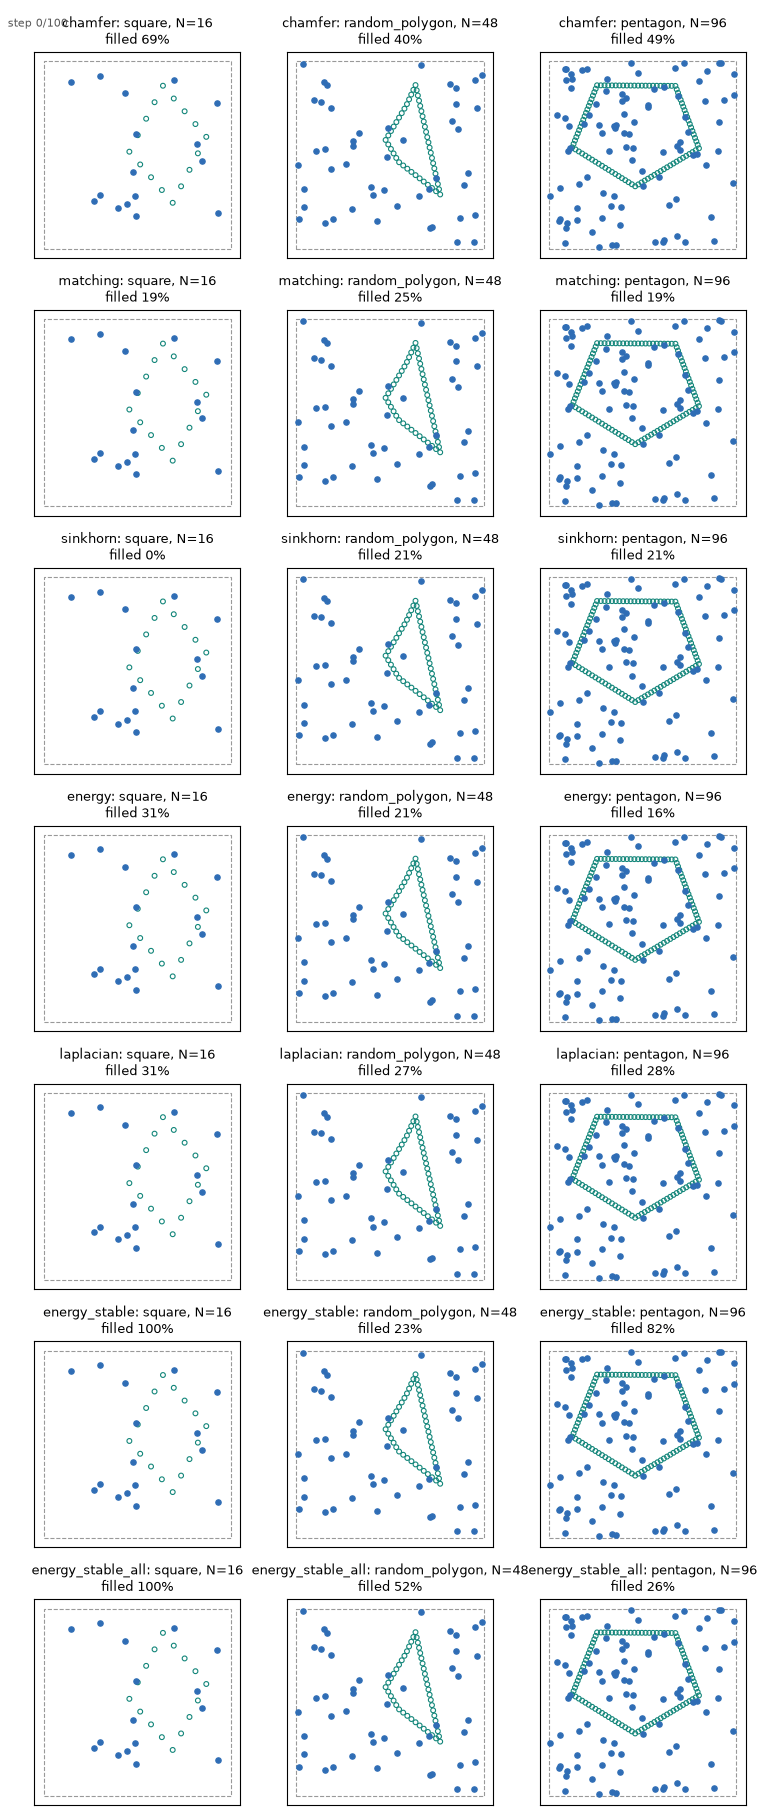

In [8]:
def scene(n, split, fam, k=0):
    c = load_cell(n, split, families=SPLITS[split]); i = [j for j, f in enumerate(c["family"]) if f == fam][k]
    return f"{fam}, N={n}", {key: c[key][i:i + 1] for key in ("start", "goals", "d_min", "anchor")}

def side_by_side(scenes, path):
    trajs, goals, titles = [], [], []
    for loss in LOSSES:
        for name, sc in scenes:
            e = evaluate_cell(policies[loss], sc, cfg)
            trajs.append(e["traj"][0]); goals.append(sc["goals"][0])
            titles.append(f"{loss}: {name}\nfilled {100 * e['filled'][0]:.0f}%")
    return viz.save_gif_grid(trajs, goals, path, titles=titles, cols=len(scenes), panel=2.6)

train_scenes = [scene(16, "train", "square"), scene(48, "train", "random_polygon"), scene(96, "train", "pentagon")]
display(Image(filename=side_by_side(train_scenes, GIFS / "phase2_losses_train.gif")))

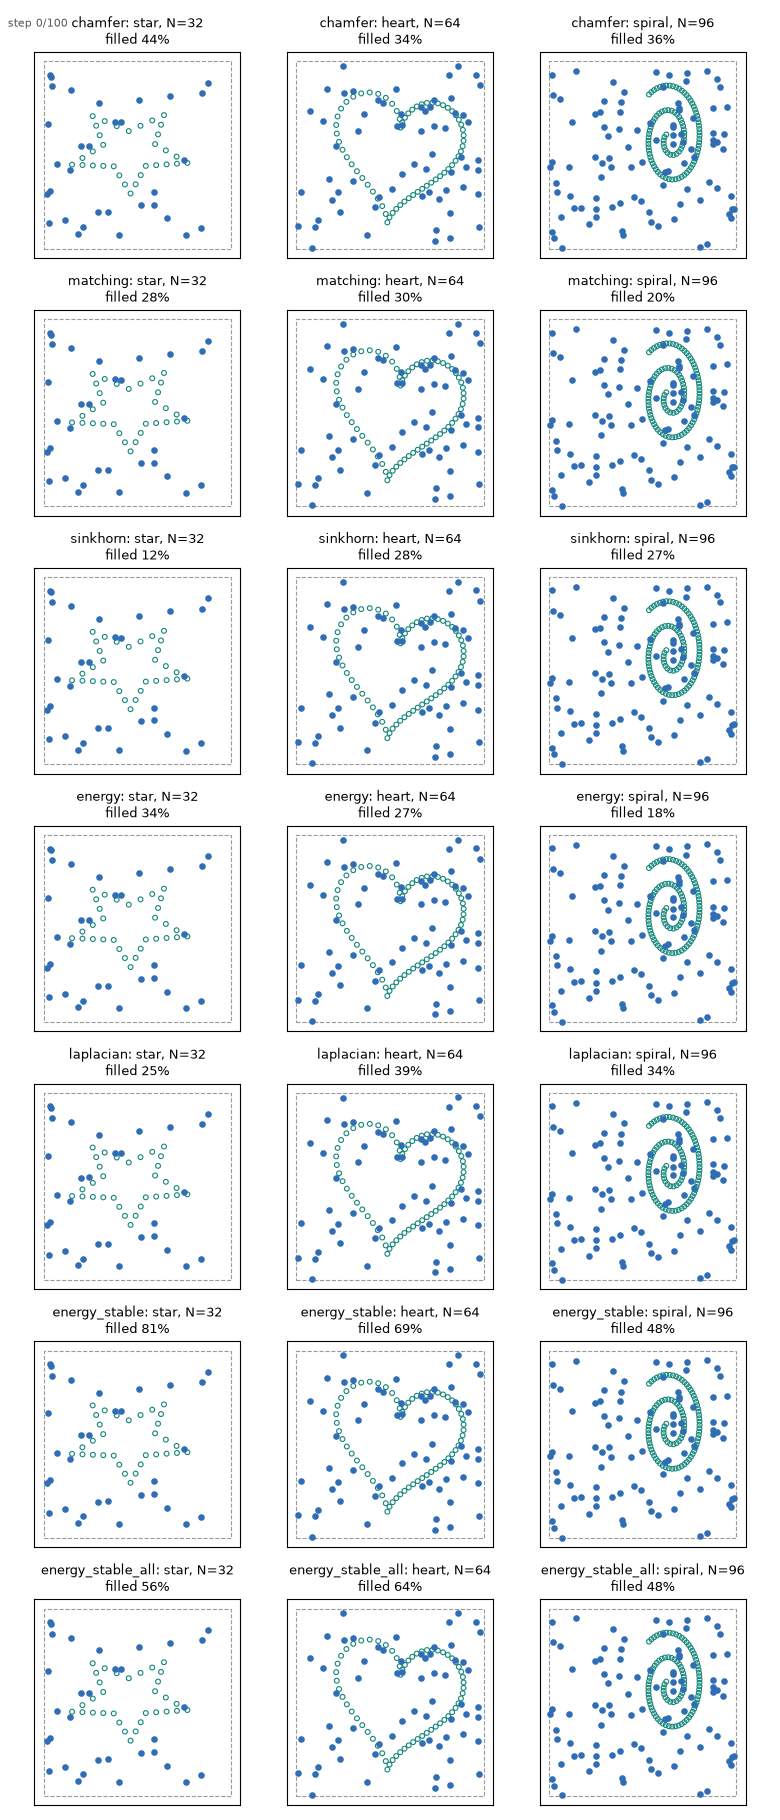

In [9]:
held_scenes = [scene(32, "heldout", "star"), scene(64, "heldout", "heart"), scene(96, "heldout", "spiral")]
display(Image(filename=side_by_side(held_scenes, GIFS / "phase2_losses_heldout.gif")))

## 8. Summary

In [10]:
Path("results/phase2_losses.json").write_text(json.dumps(summary, indent=1))
for k in LOSSES + ["optimum"]:
    t, h = summary[k]["train"], summary[k]["heldout"]
    extra = f"   speed {summary[k]['final_speed']:.3f}, switches {summary[k]['goal_switches']:.2f}" if k in hold else ""
    print(f"{k:10s} filled {100 * t['filled']:3.0f}% / held-out {100 * h['filled']:3.0f}%   slot error {t['slot_error']:.2f} / "
          f"{h['slot_error']:.2f}   formed {100 * t['formed']:3.0f}% (median step {t['steps_to_form']:.0f}){extra}")
print("saved results/phase2_losses.json")

chamfer    filled  45% / held-out  56%   slot error 2.18 / 1.21   formed  12% (median step 66)   speed 0.026, switches 0.16
matching   filled  20% / held-out  19%   slot error 1.13 / 0.99   formed   0% (median step nan)   speed 0.145, switches 2.21
sinkhorn   filled  17% / held-out  20%   slot error 1.35 / 1.02   formed   0% (median step nan)   speed 0.135, switches 2.40
energy     filled  26% / held-out  28%   slot error 1.11 / 0.82   formed   2% (median step 96)   speed 0.106, switches 1.17
laplacian  filled  30% / held-out  33%   slot error 0.95 / 0.74   formed   4% (median step 96)   speed 0.173, switches 2.17
energy_stable filled  69% / held-out  74%   slot error 0.61 / 0.51   formed  61% (median step 56)   speed 0.043, switches 0.34
energy_stable_all filled  58% / held-out  63%   slot error 0.84 / 0.62   formed  45% (median step 27)   speed 0.030, switches 0.19
optimum    filled 100% / held-out 100%   slot error 0.02 / 0.01   formed 100% (median step 72)
saved results/phase2_loss